# NYC Yellow Taxi longitudinal analysis — 2015–2026

Monthly observations describe reported Yellow Taxi activity. This notebook reads the versioned summary built by `python main.py`. For a first run, build the summary before opening this notebook.

Multi-month comparisons use the same January–August window for every year. Averages of monthly medians are labelled explicitly; they are not pooled trip-level medians.

In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve paths independently of whether Jupyter starts in the repo or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src/nyc_taxi").is_dir())
RAW = Path(os.environ.get("NYC_TAXI_RAW_DIR", str(Path.home() / "Data/raw/nyc-taxi")))
SUMMARY = Path(os.environ.get("NYC_TAXI_SUMMARY", str(Path.home() / "Data/processed/nyc-taxi/monthly_summary.parquet")))
FIGURES = ROOT / "reports/figures"


In [2]:
from nyc_taxi.validation import validate_monthly_summary
from nyc_taxi.comparison import compare_periods
from nyc_taxi.config import DEFAULT_CONFIG
from nyc_taxi.plotting import plot_monthly

df = pd.read_parquet(SUMMARY)
validate_monthly_summary(df, "2015-01", "2026-08")
if not df.processing_fingerprint.eq(DEFAULT_CONFIG.fingerprint).all():
    raise ValueError("Summary uses different analytical rules; rebuild with the default configuration")
df["period"] = pd.to_datetime(dict(year=df.year, month=df.month, day=1))
comparison = compare_periods(df, years=(2015, 2019, 2026), end_month=8)
print(f"{len(df)} months; {int(df.trip_count.sum()):,} in-period records")
display(df.head())

140 months; 831,237,097 in-period records


,year,month,raw_record_count,trip_count,outside_period_count,duration_valid_count,median_duration_min,distance_valid_count,median_distance_mi,speed_valid_count,...,duration_coverage_pct,distance_coverage_pct,speed_coverage_pct,monetary_coverage_pct,passenger_coverage_pct,ratecode_coverage_pct,processing_fingerprint,source_signature,zone_signature,period
0,2015,1,12741035,12741035,0,12715088,9.950000,12667249,1.70,12645979,...,99.796351,99.420879,99.253938,99.968087,99.999765,99.996091,31c23e2c821809fc383fcdecbc86239e90fc10253c7fa1...,175325767:1791017980379249669,1a99e105092230f8620f301edcca7f80d3080642ff404d...,2015-01-01
1,2015,2,12442394,12442394,0,12416743,10.783333,12370585,1.70,12349971,...,99.793842,99.422868,99.257193,99.966887,99.999646,99.996665,31c23e2c821809fc383fcdecbc86239e90fc10253c7fa1...,171639741:1791018002008343169,1a99e105092230f8620f301edcca7f80d3080642ff404d...,2015-02-01
2,2015,3,13342951,13342951,0,13314843,10.916667,13262901,1.70,13240046,...,99.789342,99.400058,99.228769,99.966154,99.999708,99.997422,31c23e2c821809fc383fcdecbc86239e90fc10253c7fa1...,185355459:1791018012650724244,1a99e105092230f8620f301edcca7f80d3080642ff404d...,2015-03-01
3,2015,4,13063758,13063758,0,13036072,11.183333,12986614,1.76,12965337,...,99.788070,99.409481,99.246610,99.967284,99.999694,99.997306,31c23e2c821809fc383fcdecbc86239e90fc10253c7fa1...,180491380:1791018019131666276,1a99e105092230f8620f301edcca7f80d3080642ff404d...,2015-04-01
4,2015,5,13157677,13157677,0,13126898,11.383333,13076342,1.80,13051961,...,99.766076,99.381844,99.196545,99.965837,99.999742,99.997142,31c23e2c821809fc383fcdecbc86239e90fc10253c7fa1...,182487456:1791018021342033248,1a99e105092230f8620f301edcca7f80d3080642ff404d...,2015-05-01


## 1. Recorded activity over time

Historical peak-to-low and immediate pandemic year-over-year changes answer different questions. We report both. Monthly counts also depend on the number of days in each month.

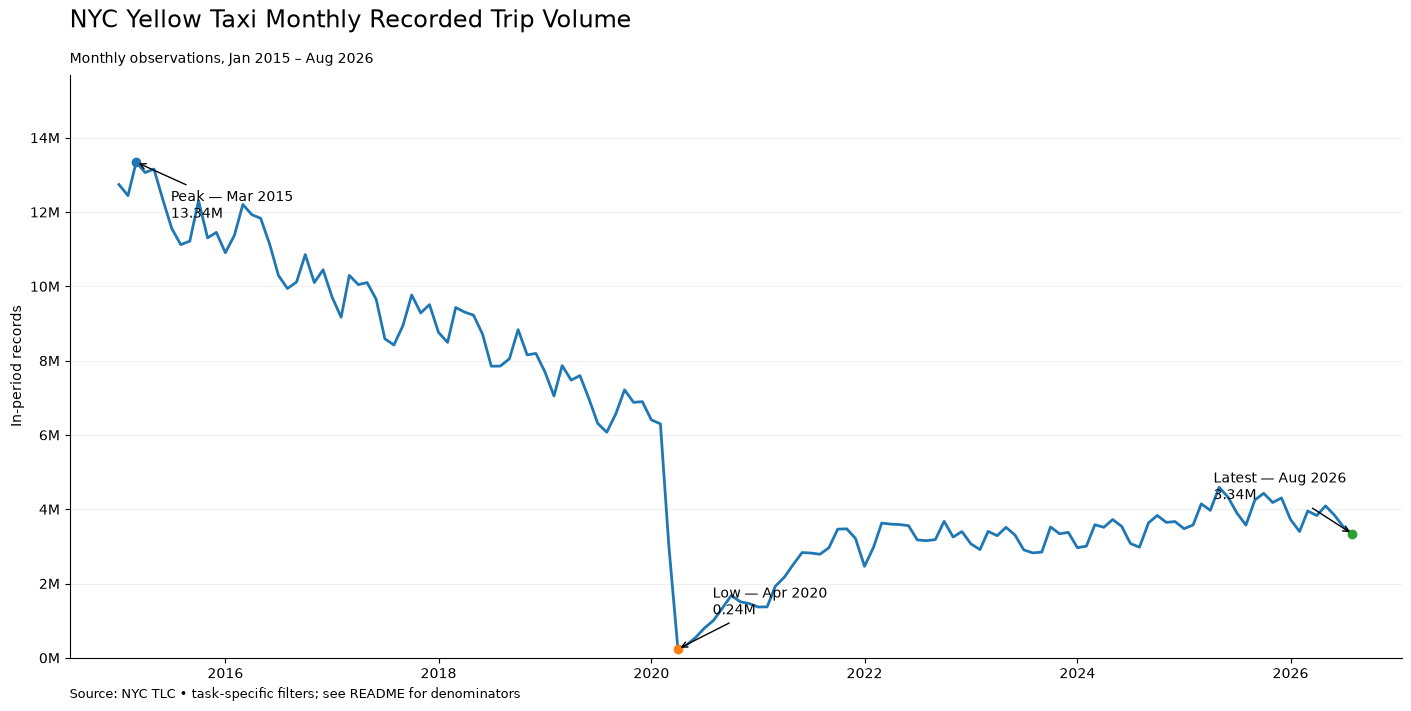

Historical peak: 2015-03, 13,342,951; low: 2020-04, 237,941.
Historical peak-to-low change: -98.22%
April 2020 versus April 2019: -96.82%
Jan–Aug 2026 versus Jan–Aug 2019 average monthly activity: -47.92%


In [3]:
plot_monthly(df, "trip_count", "NYC Yellow Taxi Monthly Recorded Trip Volume", "In-period records",
             FIGURES / "monthly_trip_volume.png", highlights=("peak", "low", "latest"))
plt.show()
peak = df.loc[df.trip_count.idxmax()]
low = df.loc[df.trip_count.idxmin()]
print(f"Historical peak: {peak.period:%Y-%m}, {int(peak.trip_count):,}; low: {low.period:%Y-%m}, {int(low.trip_count):,}.")
print(f"Historical peak-to-low change: {(low.trip_count / peak.trip_count - 1) * 100:.2f}%")
indexed = df.set_index("period")
apr_2019 = indexed.loc[pd.Timestamp("2019-04-01"), "trip_count"]
apr_2020 = indexed.loc[pd.Timestamp("2020-04-01"), "trip_count"]
print(f"April 2020 versus April 2019: {(apr_2020 / apr_2019 - 1) * 100:.2f}%")
print(f"Jan–Aug 2026 versus Jan–Aug 2019 average monthly activity: {(comparison.loc[2026, 'average_monthly_trips'] / comparison.loc[2019, 'average_monthly_trips'] - 1) * 100:.2f}%")

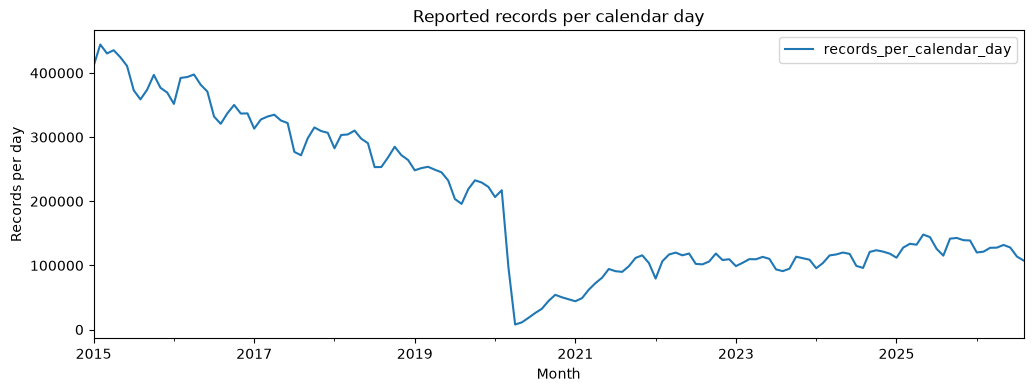

In [4]:
df.assign(records_per_calendar_day=df.trip_count / df.period.dt.days_in_month).plot(
    x="period", y="records_per_calendar_day", figsize=(12, 4), title="Reported records per calendar day", xlabel="Month", ylabel="Records per day")
plt.show()

## 2. Trip characteristics

Each point below is a median of the month's selected trip records. The cross-year table reports the arithmetic average of those monthly medians. Medians from different subsets cannot be combined to decompose speed changes.

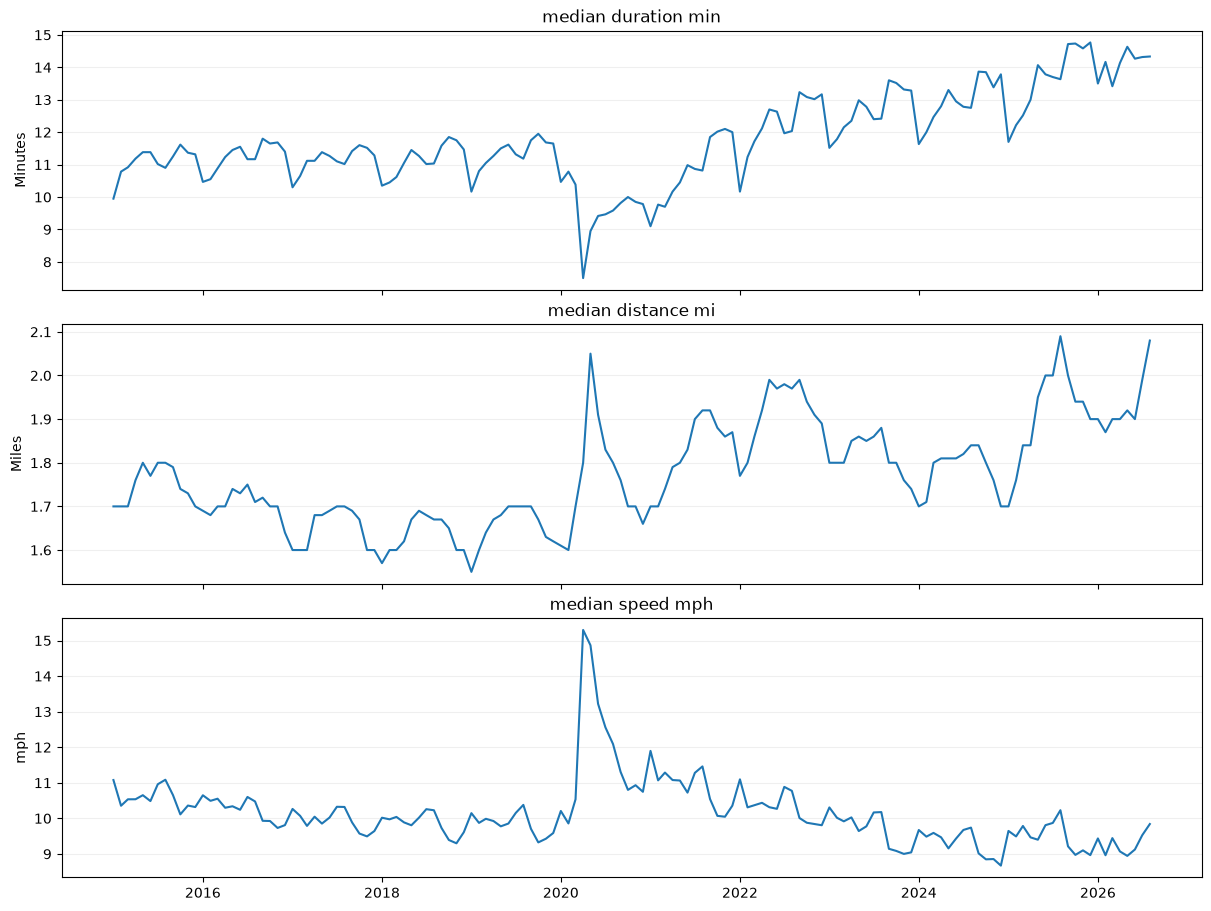

average_monthly_median_duration_min: 11.113 → 14.096; +26.85% (Jan–Aug both years)
average_monthly_median_distance_mi: 1.655 → 1.933; +16.77% (Jan–Aug both years)
average_monthly_median_speed_mph: 10.011 → 9.293; -7.17% (Jan–Aug both years)


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, layout="constrained")
for ax, column, label in zip(axes, ["median_duration_min", "median_distance_mi", "median_speed_mph"], ["Minutes", "Miles", "mph"]):
    ax.plot(df.period, df[column])
    ax.set(ylabel=label, title=column.replace("_", " "))
    ax.grid(axis="y", alpha=.2)
plt.show()
for metric in ["average_monthly_median_duration_min", "average_monthly_median_distance_mi", "average_monthly_median_speed_mph"]:
    before, after = comparison.loc[2019, metric], comparison.loc[2026, metric]
    print(f"{metric}: {before:.3f} → {after:.3f}; {(after / before - 1) * 100:+.2f}% (Jan–Aug both years)")

## 3. Recorded amounts and exclusions

Dollar values are nominal. The selected sum uses monetary-valid records; the finite signed sum also includes negative totals. They are different descriptive aggregates, and neither is net revenue. Fare rules, surcharges, inflation and trip composition may all contribute to changes.

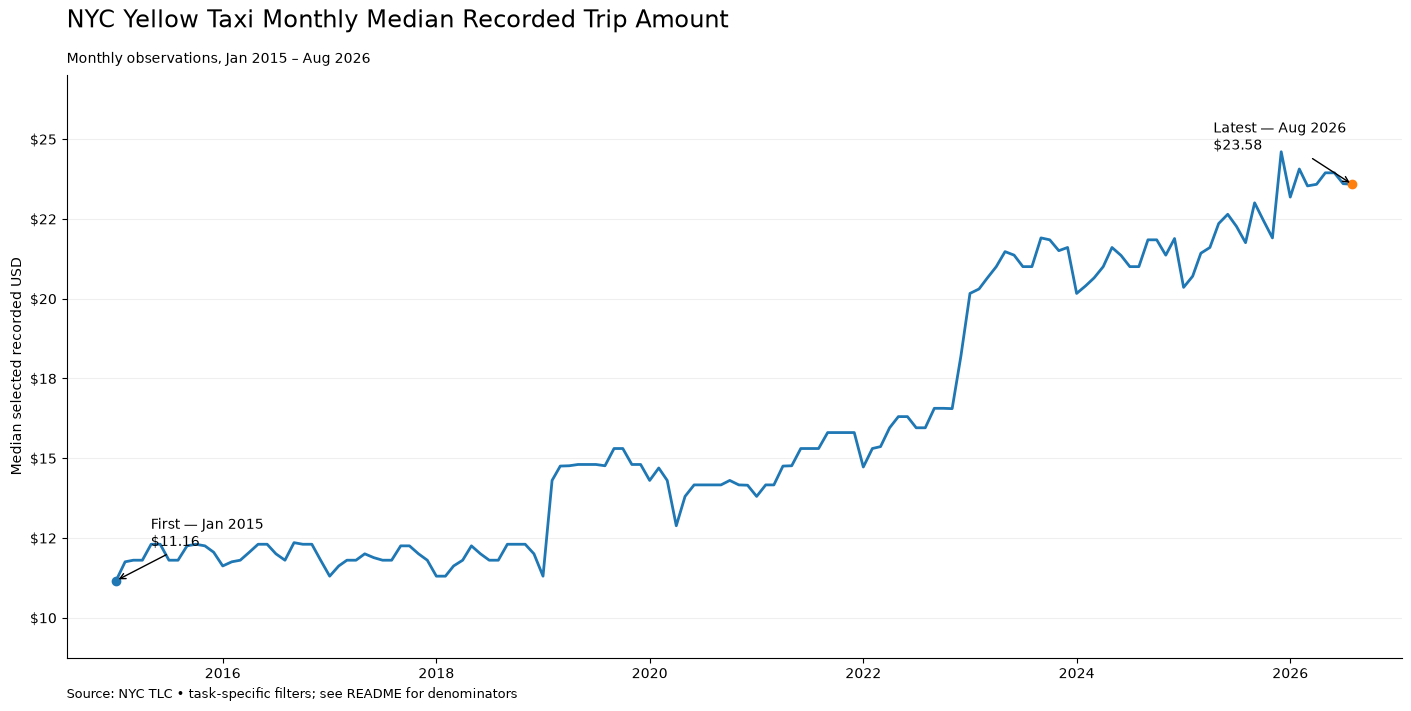

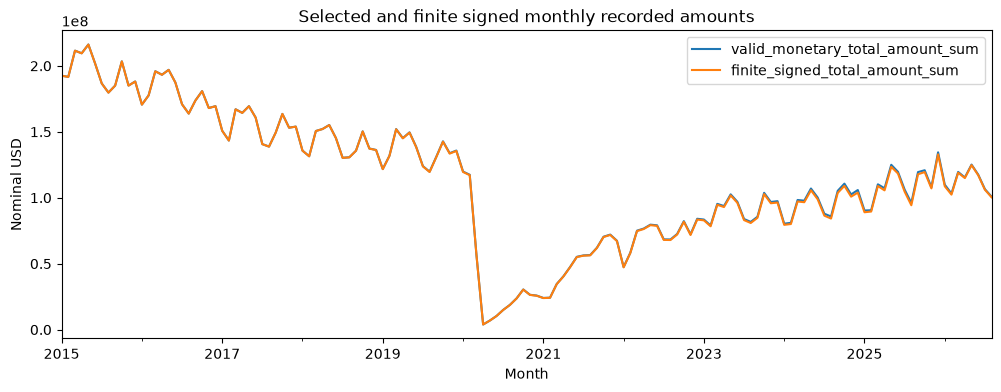

,period,monetary_excluded_count,monetary_outlier_count,max_valid_total_amount
0,2015-01-01,4066,68,3950611.60
50,2019-03-01,11829,26,1084772.17
62,2020-03-01,11033,26,1000003.80
69,2020-10-01,7360,16,998325.61
43,2018-08-01,6035,46,907071.04
120,2025-01-01,144439,79,863380.37
28,2017-05-01,5024,66,861611.05
33,2017-10-01,4645,48,861603.24
11,2015-12-01,4453,71,826039.97
80,2021-09-01,12400,14,818286.74


In [6]:
plot_monthly(df, "median_total_amount", "NYC Yellow Taxi Monthly Median Recorded Trip Amount", "Median selected recorded USD",
             FIGURES / "median_total_amount.png")
plt.show()
df.plot(x="period", y=["valid_monetary_total_amount_sum", "finite_signed_total_amount_sum"], figsize=(12, 4),
        title="Selected and finite signed monthly recorded amounts", xlabel="Month", ylabel="Nominal USD")
plt.show()
display(df[["period", "monetary_excluded_count", "monetary_outlier_count", "max_valid_total_amount"]].sort_values("max_valid_total_amount", ascending=False).head(10))

## 4. Airports and payment categories

Airport share uses known pickup zones and must be read alongside unknown-zone coverage. Credit-card share uses all in-period records. Cross-year shares aggregate counts before division, so months with more records receive their proper weight. A higher share need not mean a larger absolute number.

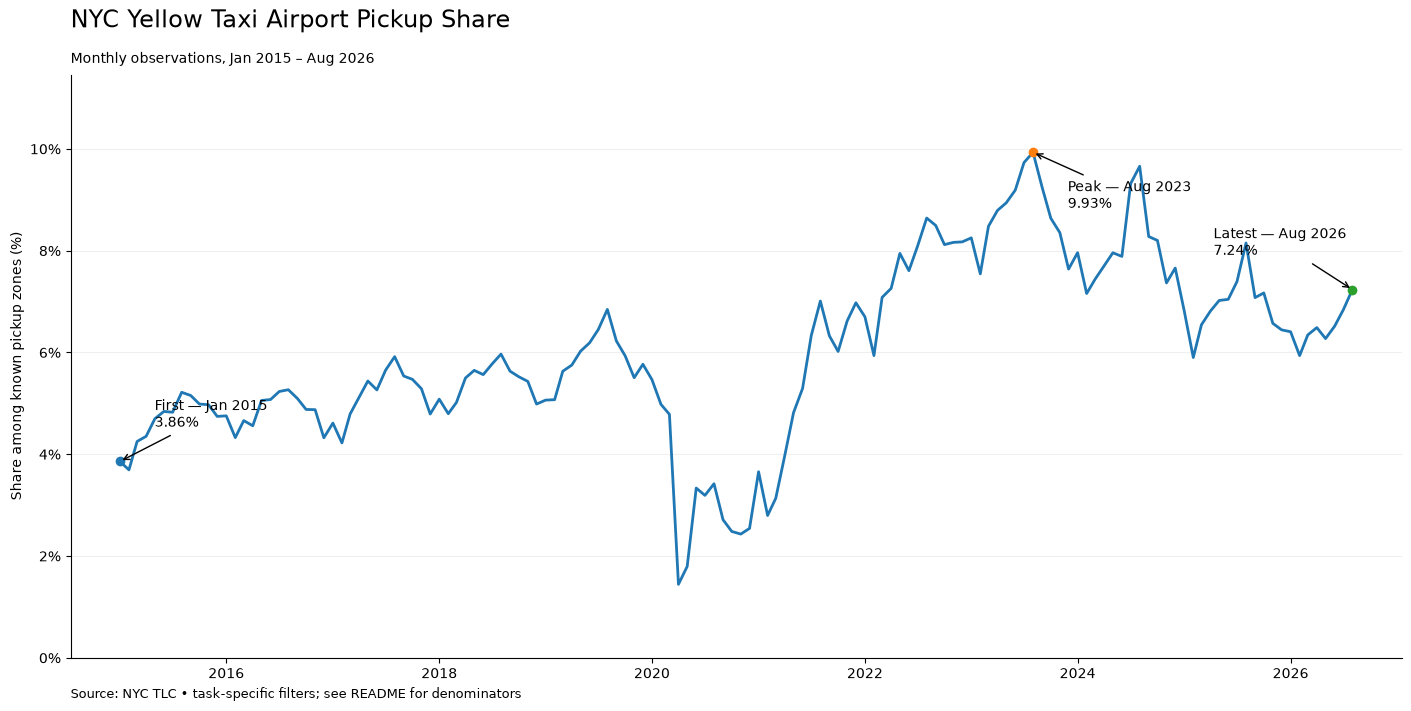

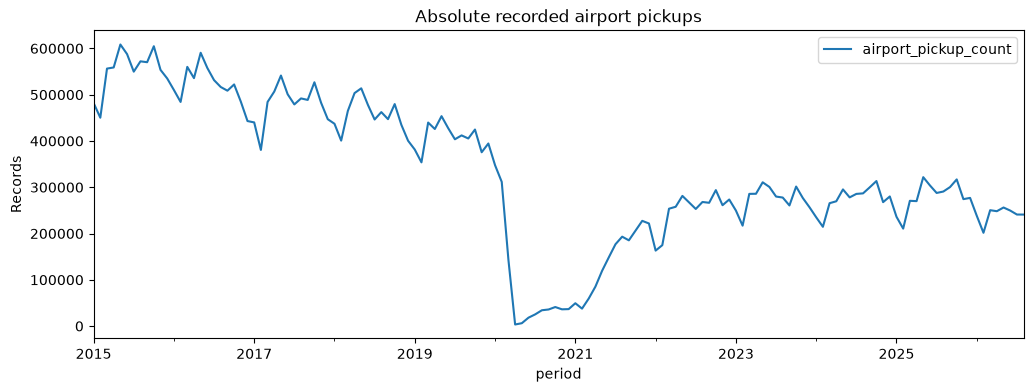

,airport_pickup_share,credit_card_share,nonflex_credit_card_share,flex_fare_share
year,,,,
2015,4.452131,62.459579,62.459587,0.000000
2019,5.843724,71.574449,71.908652,0.464706
2026,6.495445,63.767157,86.147753,25.979307


In [7]:
plot_monthly(df, "airport_pickup_share", "NYC Yellow Taxi Airport Pickup Share", "Share among known pickup zones (%)",
             FIGURES / "airport_pickup_share.png", highlights=("first", "peak", "latest"))
plt.show()
df.plot(x="period", y="airport_pickup_count", figsize=(12, 4), title="Absolute recorded airport pickups", ylabel="Records")
plt.show()
display(comparison[["airport_pickup_share", "credit_card_share", "nonflex_credit_card_share", "flex_fare_share"]])

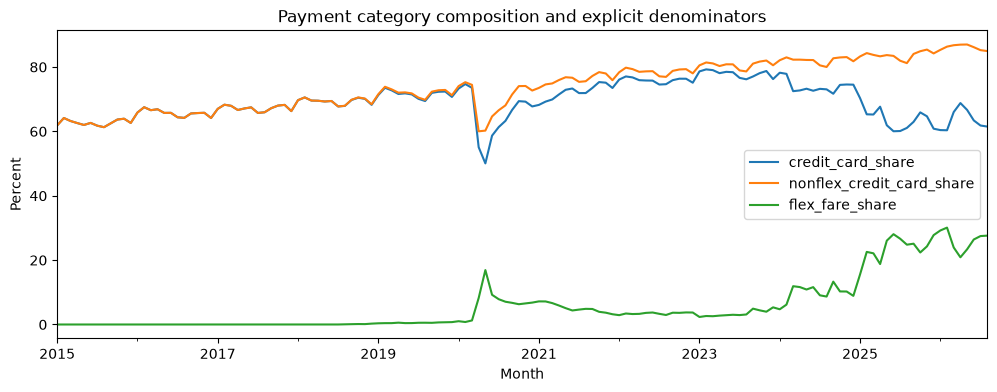

In [8]:
df["flex_fare_share"] = df.flex_fare_count / df.trip_count * 100
df.plot(x="period", y=["credit_card_share", "nonflex_credit_card_share", "flex_fare_share"], figsize=(12, 4),
        title="Payment category composition and explicit denominators", xlabel="Month", ylabel="Percent")
plt.show()

Codes 0, 5 and 6 are excluded from the non-Flex denominator; codes 1–4 remain. This measure describes observed category composition, not all passengers' underlying card/cash preferences. Airport share is not a continuously increasing trend: inspect peaks and recent declines as well as selected-year comparisons.

## 5. Quality coverage over time

If valid-record coverage changes, a metric's trend may partly reflect changing measurement or reporting. Examine coverage before interpreting a historical change as a behavioral change.

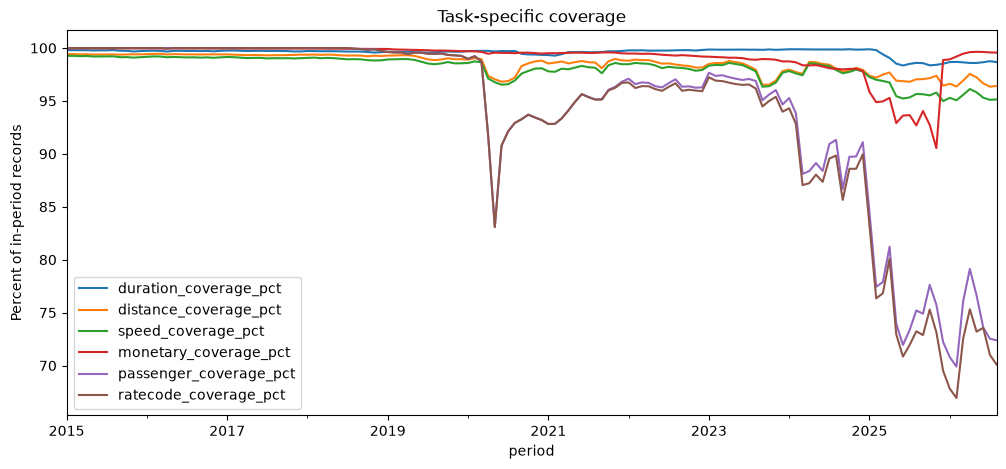

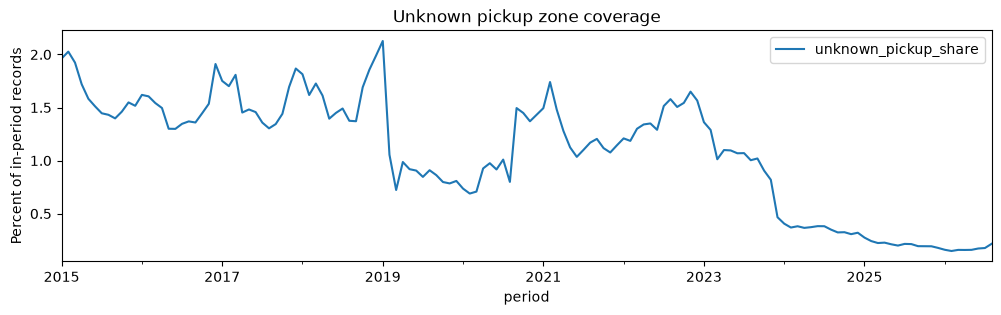

In [9]:
coverage_columns = [f"{name}_coverage_pct" for name in ["duration", "distance", "speed", "monetary", "passenger", "ratecode"]]
df.plot(x="period", y=coverage_columns, figsize=(12, 5), title="Task-specific coverage", ylabel="Percent of in-period records")
plt.show()
df.assign(unknown_pickup_share=df.pickup_zone_unknown_count / df.trip_count * 100).plot(
    x="period", y="unknown_pickup_share", figsize=(12, 3), title="Unknown pickup zone coverage", ylabel="Percent of in-period records")
plt.show()

## 6. Comparable January–August summary

All three columns cover the same eight calendar months. Every median row below is explicitly an average of monthly medians. Airport and payment rows are pooled count-based shares, not simple averages of monthly percentages.

In [10]:
labels = {
 "average_monthly_trips": "Average monthly recorded trips",
 "average_monthly_median_duration_min": "Average monthly median duration (min)",
 "average_monthly_median_distance_mi": "Average monthly median distance (mi)",
 "average_monthly_median_speed_mph": "Average monthly median speed (mph)",
 "average_monthly_median_total_amount": "Average monthly median recorded amount (USD)",
 "average_monthly_valid_monetary_total_amount_sum": "Average monthly selected monetary sum (USD)",
 "airport_pickup_share": "Airport share among known pickup zones (%)",
 "credit_card_share": "Credit-card share of all records (%)",
 "nonflex_credit_card_share": "Credit-card share among codes 1–4 (%)",
 "flex_fare_share": "Flex Fare share of all records (%)",
}
display(comparison[list(labels)].rename(columns=labels).T.round(3))
for metric in ["average_monthly_trips", "average_monthly_median_duration_min", "average_monthly_median_speed_mph", "average_monthly_median_total_amount"]:
    before, after = comparison.loc[2019, metric], comparison.loc[2026, metric]
    print(f"{labels[metric]}: {(after / before - 1) * 100:+.2f}% from 2019 to 2026")

year,2015,2019,2026
Average monthly recorded trips,1.246944e+07,7.129831e+06,3.712901e+06
Average monthly median duration (min),1.094000e+01,1.111200e+01,1.409600e+01
Average monthly median distance (mi),1.754000e+00,1.655000e+00,1.932000e+00
Average monthly median speed (mph),1.071000e+01,1.001100e+01,9.293000e+00
Average monthly median recorded amount (USD),1.183900e+01,1.428400e+01,2.367600e+01
Average monthly selected monetary sum (USD),1.987168e+08,1.353341e+08,1.122383e+08
Airport share among known pickup zones (%),4.452000e+00,5.844000e+00,6.495000e+00
Credit-card share of all records (%),6.246000e+01,7.157400e+01,6.376700e+01
Credit-card share among codes 1–4 (%),6.246000e+01,7.190900e+01,8.614800e+01
Flex Fare share of all records (%),0.000000e+00,4.650000e-01,2.597900e+01


Average monthly recorded trips: -47.92% from 2019 to 2026
Average monthly median duration (min): +26.85% from 2019 to 2026
Average monthly median speed (mph): -7.17% from 2019 to 2026
Average monthly median recorded amount (USD): +65.76% from 2019 to 2026


## Interpretation limits

These are reported Yellow Taxi records, not all NYC transport activity or unmet passenger demand. The pandemic coincides with a dramatic disruption but this descriptive analysis cannot isolate causal effects. Trip mix, vendor coverage, missing fields, analytical windows and payment categories change over time. Monetary values are nominal. A partial 2026 is compared only with matching months. See `03-quality-and-sensitivity.ipynb` for threshold sensitivity and monetary diagnostics.